# Analisis Emosi Komentar YouTube Menggunakan SVM

Notebook ini bertujuan untuk mengklasifikasikan emosi pada komentar YouTube menggunakan algoritma **Support Vector Machine (SVM)**.

---

## Alur Proses:
1. **Import Library** - Memuat library yang diperlukan
2. **Load Data** - Membaca dataset yang sudah dilabeli dan dipreprocessing
3. **Visualisasi** - WordCloud per emosi
4. **Feature Extraction** - TF-IDF
5. **Split Data** - Training dan testing
6. **Training Model** - SVM dengan class_weight balanced
7. **Evaluasi** - Classification Report dan Confusion Matrix
8. **Testing** - Prediksi contoh baru

In [1]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.3 MB/s eta 0:00:00


---
## Step 1: Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
from wordcloud import WordCloud

---
## Step 2: Load Data

Membaca dataset yang sudah dilabeli emosi dan dipreprocessing dari notebook sebelumnya.

In [3]:
# Load dataset yang sudah dilabeli dan dipreprocessing
df = pd.read_csv('youtube_comment_emotion_labeled.csv')

print(f"Jumlah Data: {len(df)}")
print(f"Kolom yang tersedia: {df.columns.tolist()}")
df.head()

Jumlah Data: 11271
Kolom yang tersedia: ['publishedAt', 'authorDisplayName', 'textDisplay', 'likeCount', 'clean_text', 'clean_text_processed', 'emotion_label']


,publishedAt,authorDisplayName,textDisplay,likeCount,clean_text,clean_text_processed,emotion_label
0,2025-12-09T02:24:10Z,@Nekokun-k8k,Makasih berkat anda gua jadi bodoh amat kemarin,0,makasih berkat anda gua jadi bodoh amat kemarin,makasih berkat bodoh kemarin,neutral
1,2025-12-03T16:05:46Z,@joviputr1238,Anak abah CS DAN BANTENG pasti pada emosi 😅 k...,0,anak abah cs dan banteng pasti pada emosi kare...,anak abah cs banteng emosi rencana gagal,anticipation
2,2025-11-22T18:29:33Z,@rudiumardani5494,Tau enggak china pki....tai china bangsat....b...,0,tau enggak china pkitai china bangsatbrengsekg...,tau china pkitai china bangsatbrengsekgua tumb...,disgust
3,2025-11-22T18:28:20Z,@rudiumardani5494,Harusnya elu susul tuh si atheis LEE KUAN YEW...,0,harusnya elu susul tuh si atheis lee kuan yewb...,elu susul tuh si atheis lee kuan yewbin poorlion,neutral
4,2025-11-20T03:55:24Z,@Bossge1091,Terlalu banyak otak kosong dan terlalu banyak ...,1,terlalu banyak otak kosong dan terlalu banyak ...,otak kosong penjilat negara apapun bersuara pe...,neutral


In [4]:
# Tampilkan distribusi label emosi
print("Distribusi Label Emosi:")
print(df['emotion_label'].value_counts())

Distribusi Label Emosi:
emotion_label
neutral         5240
anger           1375
trust           1298
fear            1261
anticipation     860
disgust          526
joy              363
sadness          288
surprise          60
Name: count, dtype: int64


In [5]:
# Hapus baris dengan nilai kosong
df = df.dropna(subset=['clean_text_processed', 'emotion_label'])
df = df[df['clean_text_processed'].str.strip() != '']

print(f"Jumlah data setelah cleaning: {len(df)}")
print(f"\nDistribusi label:")
print(df['emotion_label'].value_counts())

Jumlah data setelah cleaning: 10963

Distribusi label:
emotion_label
neutral         4932
anger           1375
trust           1298
fear            1261
anticipation     860
disgust          526
joy              363
sadness          288
surprise          60
Name: count, dtype: int64


---
## Step 3: Visualisasi WordCloud

Menampilkan kata-kata yang sering muncul per kategori emosi.

In [6]:
def generate_wordcloud(text_series, title):
    """Membuat WordCloud dari series teks"""
    text = " ".join(text_series.dropna().astype(str))

    if len(text.strip()) == 0:
        print(f"Tidak ada data untuk: {title}")
        return

    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        collocations=False,
        max_words=100
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

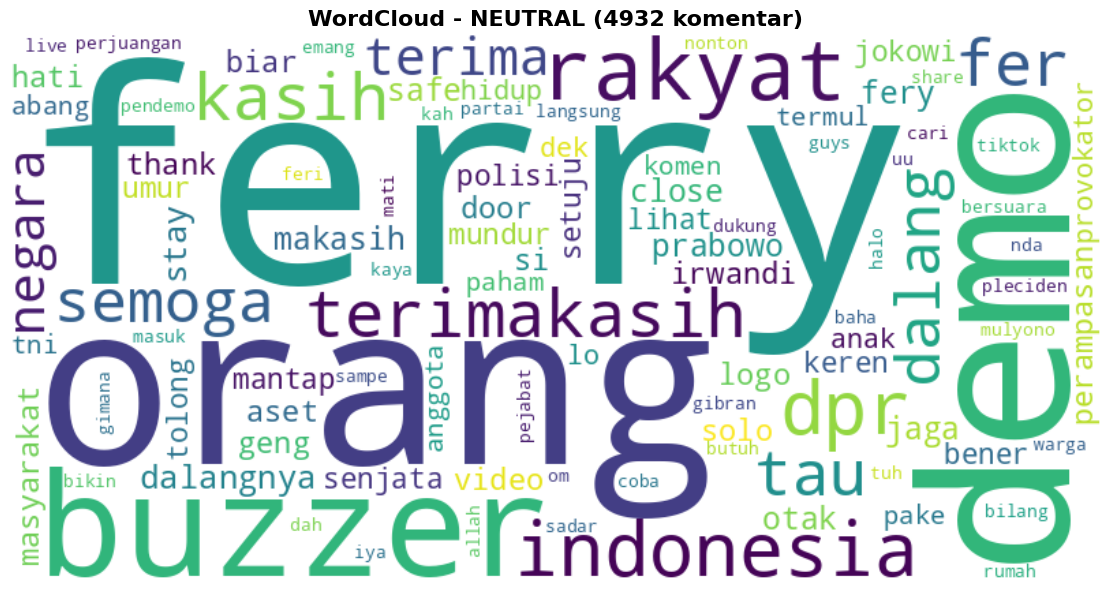

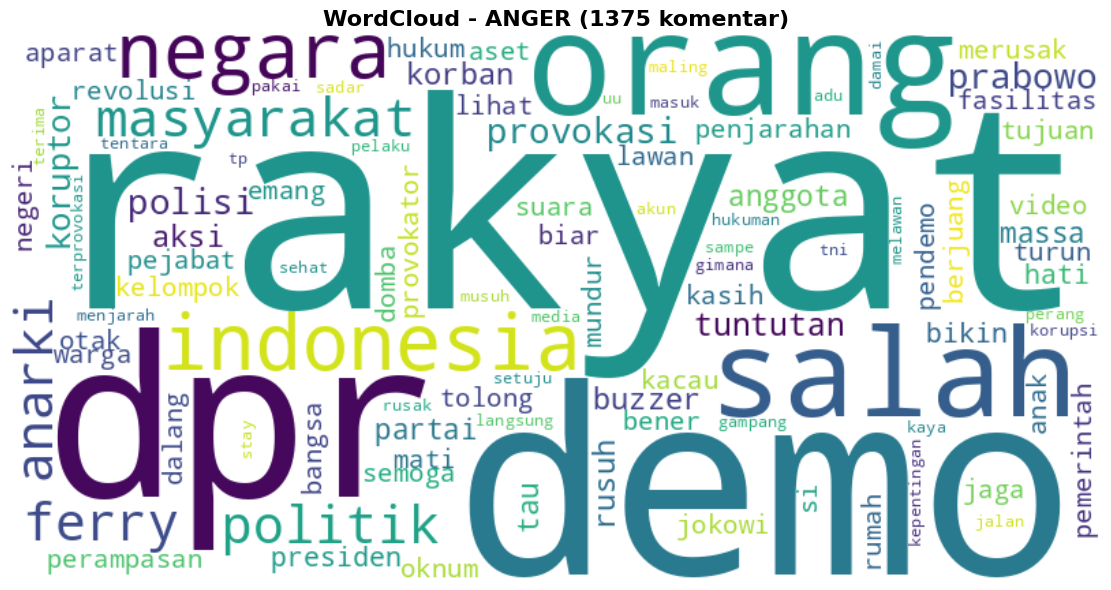

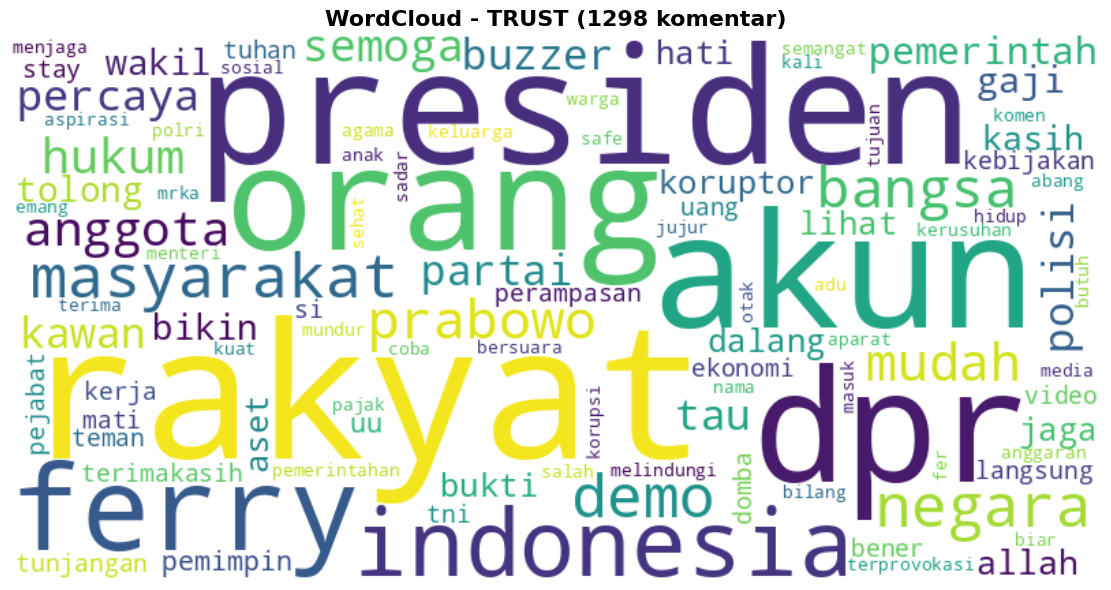

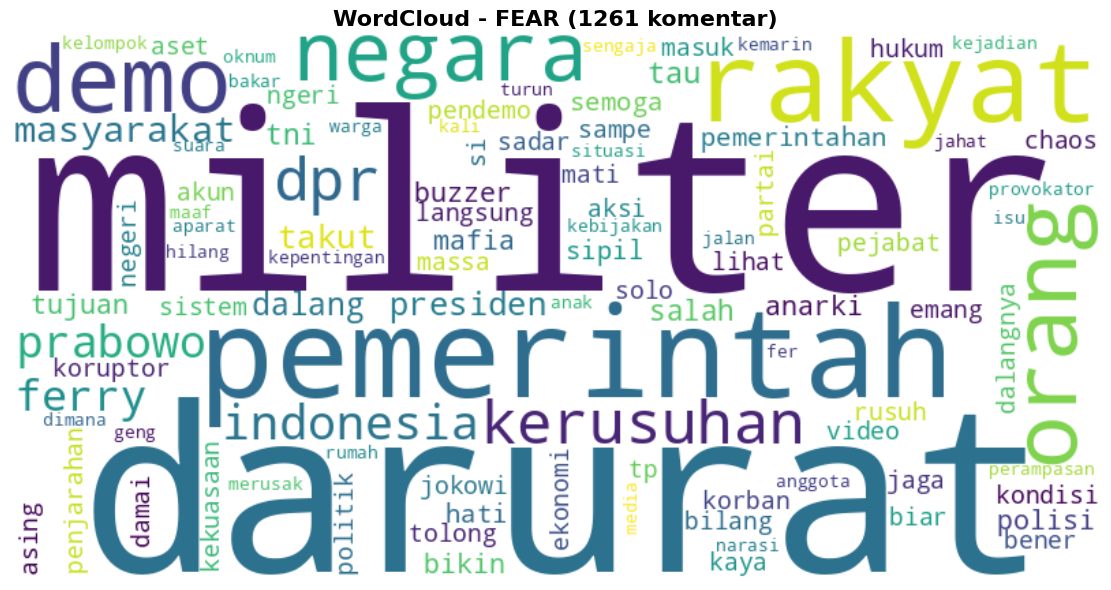

In [7]:
# WordCloud untuk 4 emosi teratas
top_emotions = df['emotion_label'].value_counts().head(4).index.tolist()

for emotion in top_emotions:
    subset = df[df['emotion_label'] == emotion]['clean_text_processed']
    generate_wordcloud(subset, f'WordCloud - {emotion.upper()} ({len(subset)} komentar)')

---
## Step 4: Feature Extraction (TF-IDF)

Mengubah teks menjadi representasi numerik menggunakan TF-IDF.

In [8]:
# Inisialisasi TF-IDF Vectorizer
vectorizer = TfidfVectorizer(
    max_features=3000,      # Maksimal 3000 fitur
    ngram_range=(1, 2),     # Unigram dan bigram
    min_df=2                # Minimal muncul di 2 dokumen
)

# Transformasi teks menjadi fitur numerik
X = vectorizer.fit_transform(df['clean_text_processed'])
y = df['emotion_label']

print(f"Dimensi Fitur: {X.shape}")
print(f"Jumlah Label Unik: {y.nunique()}")

Dimensi Fitur: (10963, 3000)
Jumlah Label Unik: 9


---
## Step 5: Split Data (Training & Testing)

- **80% Training** - untuk melatih model
- **20% Testing** - untuk mengevaluasi model

In [9]:
# Split Data dengan stratify (menjaga proporsi label)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"Data Training: {X_train.shape[0]}")
print(f"Data Testing: {X_test.shape[0]}")

Data Training: 8770
Data Testing: 2193


---
## Step 6: Training Model SVM

Menggunakan `class_weight='balanced'` untuk menangani ketidakseimbangan data antar kelas emosi.

In [10]:
# Inisialisasi dan Training Model SVM
model = LinearSVC(class_weight='balanced')
model.fit(X_train, y_train)

print("Model berhasil ditraining!")

Model berhasil ditraining!


---
## Step 7: Evaluasi Model

- **Accuracy** - Persentase prediksi yang benar
- **Classification Report** - Precision, Recall, F1-Score per kelas
- **Confusion Matrix** - Visualisasi prediksi vs aktual

In [11]:
# Prediksi pada data testing
y_pred = model.predict(X_test)

# Hitung Akurasi
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi: {accuracy:.2f}")

# Classification Report
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

Akurasi: 0.85

=== Classification Report ===
              precision    recall  f1-score   support

       anger       0.79      0.74      0.77       275
anticipation       0.71      0.69      0.70       172
     disgust       0.82      0.86      0.84       105
        fear       0.86      0.83      0.85       252
         joy       0.82      0.77      0.79        73
     neutral       0.92      0.96      0.94       986
     sadness       0.63      0.66      0.64        58
    surprise       0.40      0.33      0.36        12
       trust       0.86      0.80      0.83       260

    accuracy                           0.85      2193
   macro avg       0.76      0.74      0.75      2193
weighted avg       0.85      0.85      0.85      2193



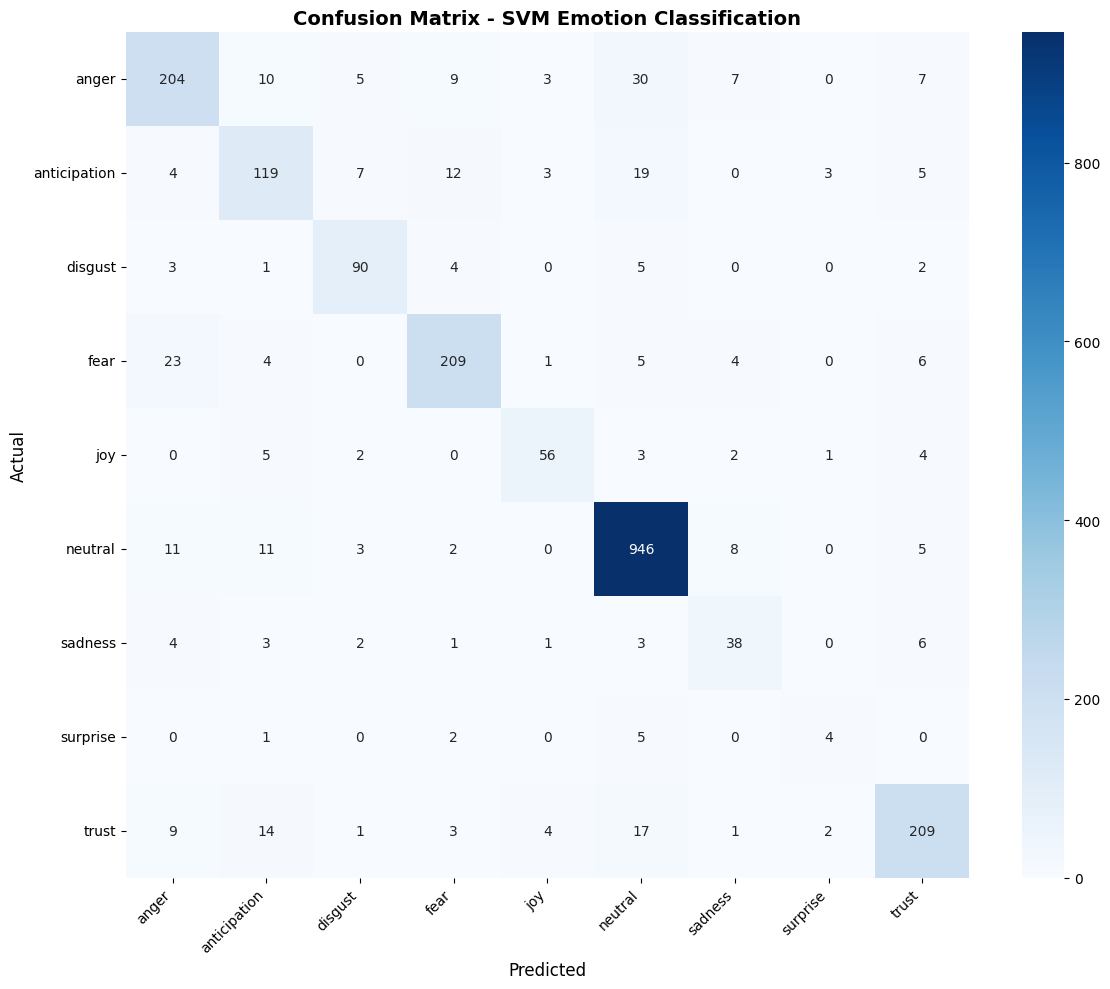

In [12]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_,
            yticklabels=model.classes_)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.title('Confusion Matrix - SVM Emotion Classification', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Step 8: Testing dengan Contoh Baru

Menguji model dengan contoh kalimat baru.

In [13]:
# Contoh kalimat baru untuk prediksi
sample_text = [
    "videonya sangat bagus saya suka sekali",
    "dasar bodoh pembohong semua",
    "sedih banget lihat kondisi ini",
    "takut banget kalau ini terjadi",
    "percaya sama pemerintah pasti bisa"
]

# Transformasi dan Prediksi
sample_vec = vectorizer.transform(sample_text)
predictions = model.predict(sample_vec)

# Tampilkan Hasil
print("=== Hasil Prediksi ===")
for text, pred in zip(sample_text, predictions):
    print(f"\nTeks: {text}")
    print(f"Prediksi Emosi: {pred}")

=== Hasil Prediksi ===

Teks: videonya sangat bagus saya suka sekali
Prediksi Emosi: anticipation

Teks: dasar bodoh pembohong semua
Prediksi Emosi: neutral

Teks: sedih banget lihat kondisi ini
Prediksi Emosi: sadness

Teks: takut banget kalau ini terjadi
Prediksi Emosi: fear

Teks: percaya sama pemerintah pasti bisa
Prediksi Emosi: fear


---
## Kesimpulan

Notebook ini telah berhasil:
1. Memuat dataset komentar YouTube yang telah dilabeli emosi
2. Mengekstraksi fitur menggunakan TF-IDF
3. Melatih model SVM untuk klasifikasi emosi
4. Mengevaluasi performa model dengan berbagai metrik

**Catatan Penting:**
- Model menggunakan `class_weight='balanced'` untuk menangani ketidakseimbangan data
- Data sudah dipreprocessing di notebook pelabelan (stopwords & singkatan)